In [50]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split

from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import StandardScaler

from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.metrics import confusion_matrix

from sklearn.metrics import accuracy_score

In [3]:
df = pd.read_csv("ford.csv")

In [4]:
print(df.head())
print(df.columns)

     model  year  price transmission  mileage fuelType  tax   mpg  engineSize
0   Fiesta  2017  12000    Automatic    15944   Petrol  150  57.7         1.0
1    Focus  2018  14000       Manual     9083   Petrol  150  57.7         1.0
2    Focus  2017  13000       Manual    12456   Petrol  150  57.7         1.0
3   Fiesta  2019  17500       Manual    10460   Petrol  145  40.3         1.5
4   Fiesta  2019  16500    Automatic     1482   Petrol  145  48.7         1.0
Index(['model', 'year', 'price', 'transmission', 'mileage', 'fuelType', 'tax',
       'mpg', 'engineSize'],
      dtype='str')


In [5]:
print(df.isnull().sum())

model           0
year            0
price           0
transmission    0
mileage         0
fuelType        0
tax             0
mpg             0
engineSize      0
dtype: int64


In [6]:
label_encoder = LabelEncoder()

for column in df.columns:
    if df[column].dtype == "object":
        df[column] = label_encoder.fit_transform(df[column])

In [21]:
from sklearn.preprocessing import LabelEncoder

label_encoder = LabelEncoder()

categorical_columns = df.select_dtypes(
    include=["object", "string"]
).columns

for column in categorical_columns:
    df[column] = label_encoder.fit_transform(df[column])

print(df.head())

   model  year  price  transmission  mileage  fuelType  tax   mpg  engineSize
0      5  2017  12000             0    15944         4  150  57.7         1.0
1      6  2018  14000             1     9083         4  150  57.7         1.0
2      6  2017  13000             1    12456         4  150  57.7         1.0
3      5  2019  17500             1    10460         4  145  40.3         1.5
4      5  2019  16500             0     1482         4  145  48.7         1.0


In [22]:
df

,model,year,price,transmission,mileage,fuelType,tax,mpg,engineSize
0,5,2017,12000,0,15944,4,150,57.7,1.0
1,6,2018,14000,1,9083,4,150,57.7,1.0
2,6,2017,13000,1,12456,4,150,57.7,1.0
3,5,2019,17500,1,10460,4,145,40.3,1.5
4,5,2019,16500,0,1482,4,145,48.7,1.0
...,...,...,...,...,...,...,...,...,...
17961,0,2017,8999,1,16700,4,150,47.1,1.4
17962,0,2014,7499,1,40700,4,30,57.7,1.0
17963,6,2015,9999,1,7010,0,20,67.3,1.6
17964,11,2018,8299,1,5007,4,145,57.7,1.2


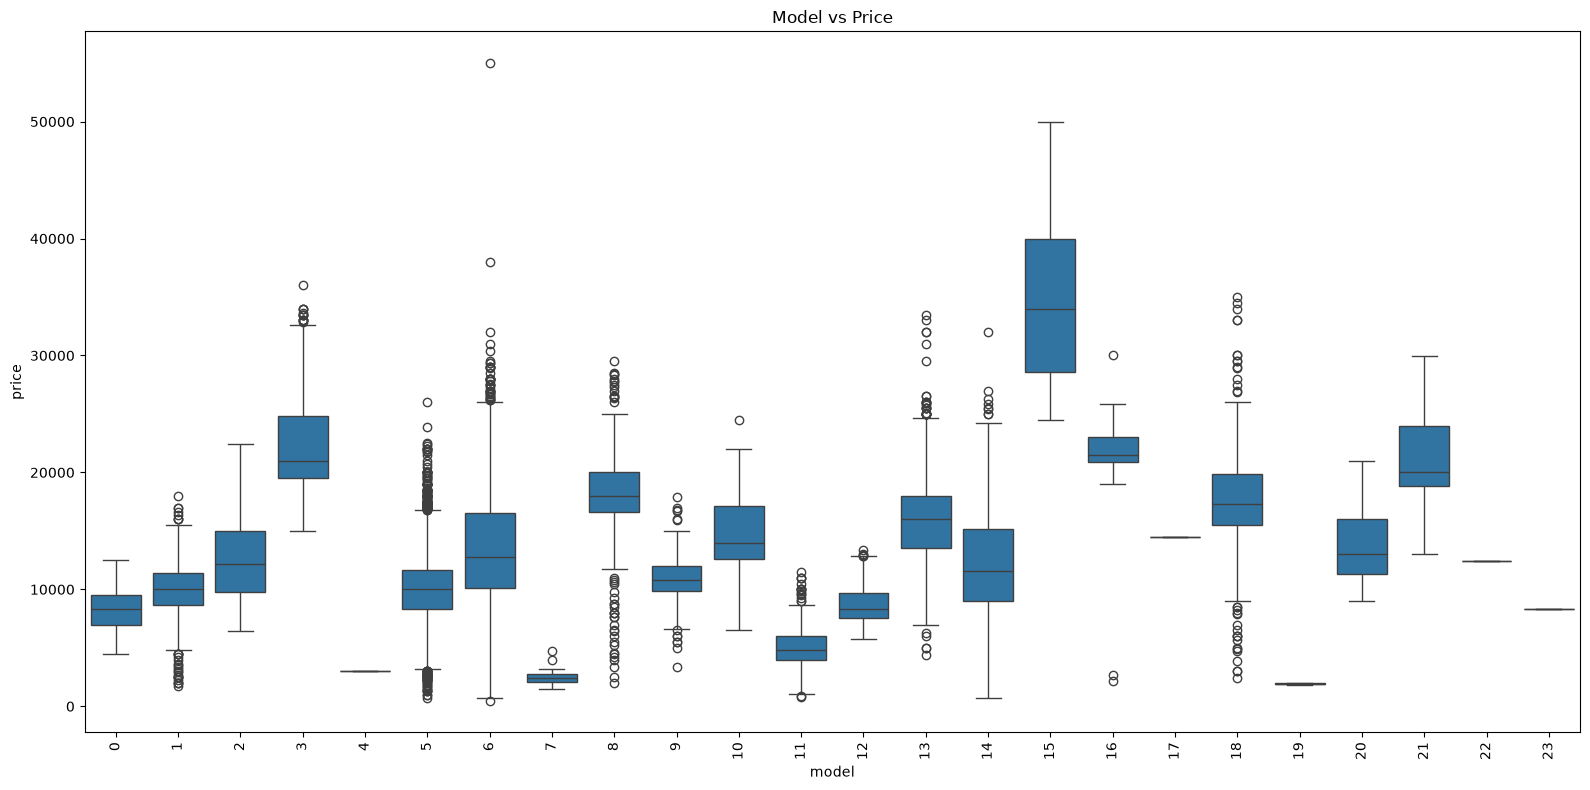

In [26]:
plt.figure(figsize=(16, 8))

sns.boxplot(
    x="model",
    y="price",
    data=df
)

plt.title("Model vs Price")
plt.xticks(rotation=90)

plt.tight_layout()
plt.show()

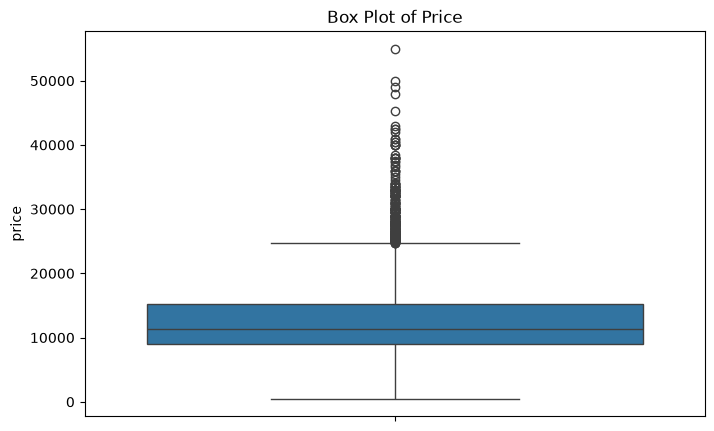

In [9]:
plt.figure(figsize=(8, 5))

sns.boxplot(y=df["price"])

plt.title("Box Plot of Price")

plt.show()

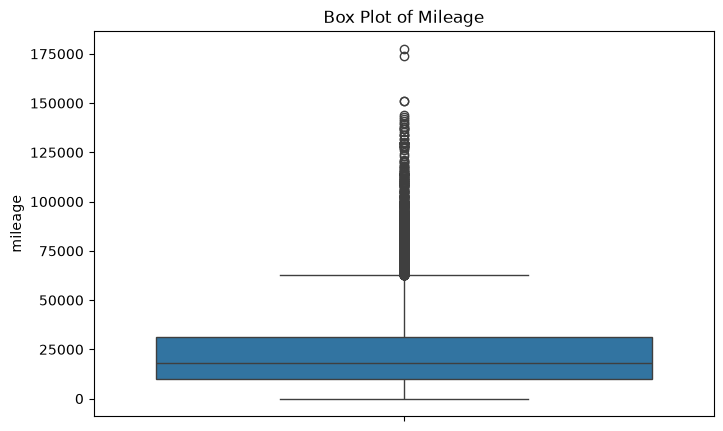

In [27]:
plt.figure(figsize=(8, 5))

sns.boxplot(y=df["mileage"])

plt.title("Box Plot of Mileage")

plt.show()

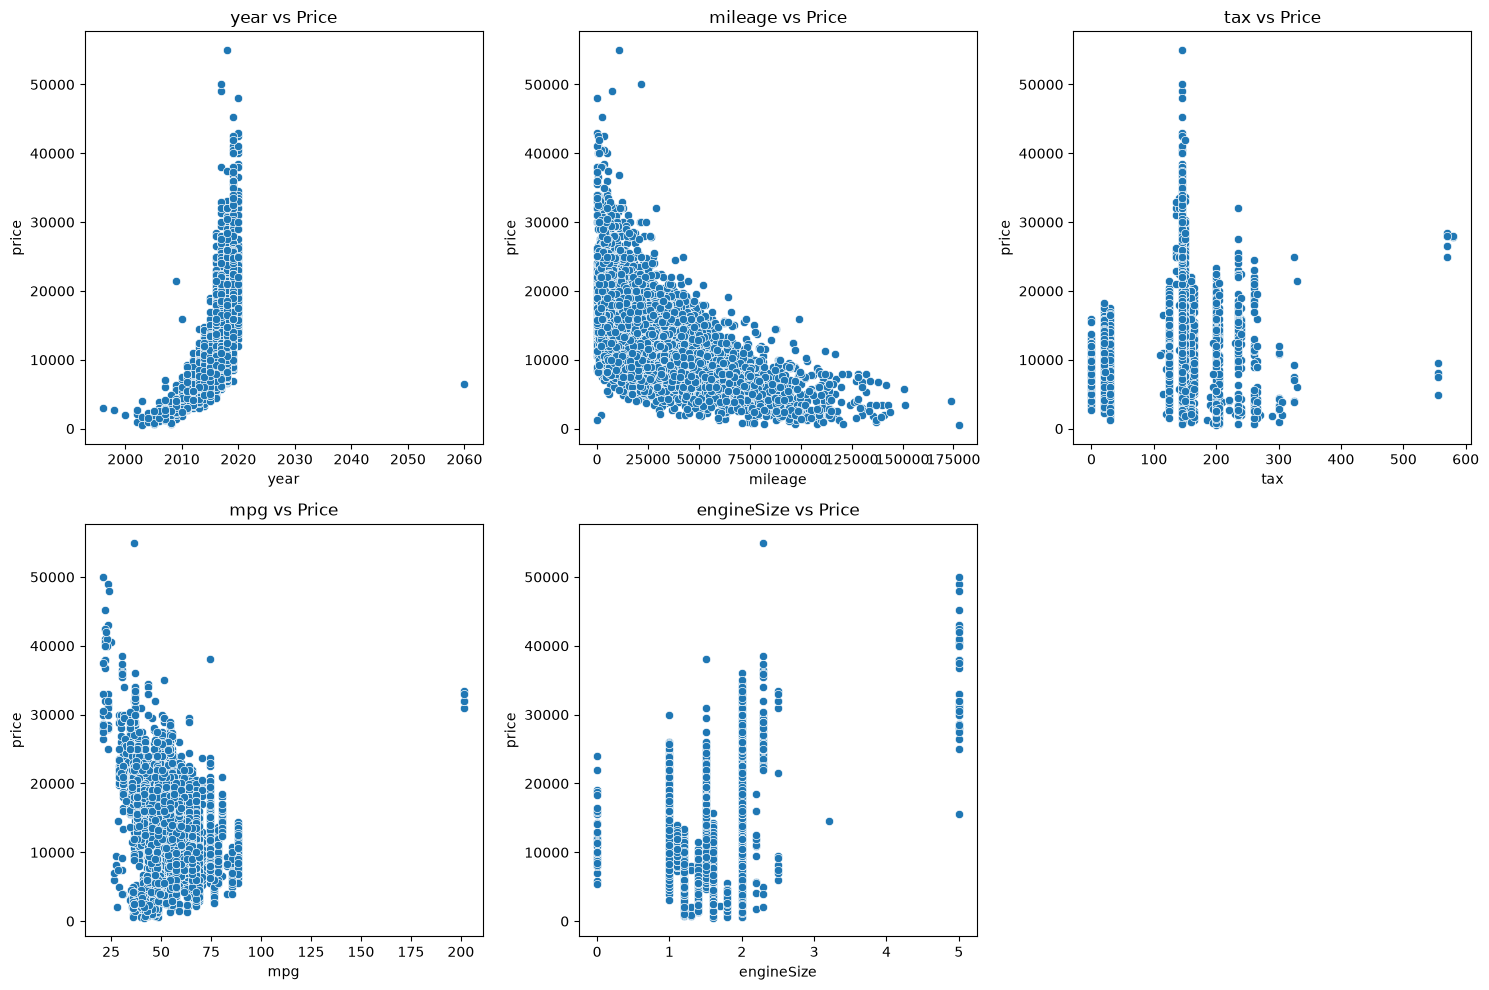

In [28]:
numerical_features = [
    "year",
    "mileage",
    "tax",
    "mpg",
    "engineSize"
]

plt.figure(figsize=(15, 10))

for i, feature in enumerate(numerical_features, 1):

    plt.subplot(2, 3, i)

    sns.scatterplot(
        x=df[feature],
        y=df["price"]
    )

    plt.title(f"{feature} vs Price")

plt.tight_layout()
plt.show()

In [12]:
numerical_columns = [
    "year",
    "price",
    "mileage",
    "tax",
    "mpg",
    "engineSize"
]

correlation_with_price = (
    df[numerical_columns]
    .corr()["price"]
    .drop("price")
    .sort_values(key=abs, ascending=False)
)

print("Correlation of attributes with Price:")
print(correlation_with_price)

Correlation of attributes with Price:
year          0.636009
mileage      -0.530659
engineSize    0.411178
tax           0.406857
mpg          -0.346419
Name: price, dtype: float64


In [39]:
X = df[
    [
        "model",
        "year",
        "transmission",
        "mileage",
        "fuelType",
        "tax",
        "mpg",
        "engineSize"
    ]
]





In [38]:
df["price_category"] = pd.qcut(
    df["price"],
    q=3,
    labels=[0, 1, 2]
)

In [40]:
print(df[["price", "price_category"]].head())

   price price_category
0  12000              1
1  14000              2
2  13000              1
3  17500              2
4  16500              2


In [41]:
X = df.drop(["price", "price_category"], axis=1)

y = df["price_category"]

In [42]:
y = y.astype(int)

In [29]:
X

,model,year,transmission,mileage,fuelType,tax,mpg,engineSize
0,5,2017,0,15944,4,150,57.7,1.0
1,6,2018,1,9083,4,150,57.7,1.0
2,6,2017,1,12456,4,150,57.7,1.0
3,5,2019,1,10460,4,145,40.3,1.5
4,5,2019,0,1482,4,145,48.7,1.0
...,...,...,...,...,...,...,...,...
17961,0,2017,1,16700,4,150,47.1,1.4
17962,0,2014,1,40700,4,30,57.7,1.0
17963,6,2015,1,7010,0,20,67.3,1.6
17964,11,2018,1,5007,4,145,57.7,1.2


In [43]:
y

0        1
1        2
2        1
3        2
4        2
        ..
17961    0
17962    0
17963    1
17964    0
17965    0
Name: price_category, Length: 17966, dtype: int64

In [44]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [45]:
print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

X_train shape: (14372, 8)
X_test shape: (3594, 8)
y_train shape: (14372,)
y_test shape: (3594,)


In [46]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)

In [ ]:
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

In [47]:
lr_model = LogisticRegression(max_iter=1000)

lr_model.fit(X_train_scaled, y_train)

lr_pred = lr_model.predict(X_test_scaled)

In [48]:
lr_accuracy = accuracy_score(y_test, lr_pred)

print("Logistic Regression Accuracy:", lr_accuracy)

Logistic Regression Accuracy: 0.7548692264885921


In [51]:
lr_cm = confusion_matrix(y_test, lr_pred)

print("Logistic Regression Confusion Matrix:")
print(lr_cm)

Logistic Regression Confusion Matrix:
[[ 884  298   36]
 [ 194  793  206]
 [   8  139 1036]]


In [52]:
dt_model = DecisionTreeClassifier(
    random_state=42
)

dt_model.fit(X_train, y_train)

dt_pred = dt_model.predict(X_test)

In [53]:
dt_accuracy = accuracy_score(y_test, dt_pred)

print("Decision Tree Accuracy:", dt_accuracy)

Decision Tree Accuracy: 0.8274902615470228


In [54]:
dt_cm = confusion_matrix(y_test, dt_pred)

print("Decision Tree Confusion Matrix:")
print(dt_cm)

Decision Tree Confusion Matrix:
[[1033  184    1]
 [ 175  888  130]
 [   1  129 1053]]


In [55]:
knn_model = KNeighborsClassifier(
    n_neighbors=5
)

knn_model.fit(X_train_scaled, y_train)

knn_pred = knn_model.predict(X_test_scaled)

In [56]:
knn_accuracy = accuracy_score(y_test, knn_pred)

print("KNN Accuracy:", knn_accuracy)

KNN Accuracy: 0.8636616583194212


In [57]:
knn_cm = confusion_matrix(y_test, knn_pred)

print("KNN Confusion Matrix:")
print(knn_cm)

KNN Confusion Matrix:
[[1071  145    2]
 [ 118  963  112]
 [   1  112 1070]]


In [58]:
svc_model = SVC()

svc_model.fit(X_train_scaled, y_train)

svc_pred = svc_model.predict(X_test_scaled)

In [59]:
svc_accuracy = accuracy_score(y_test, svc_pred)

print("SVC Accuracy:", svc_accuracy)

SVC Accuracy: 0.8461324429604897


In [60]:
svc_cm = confusion_matrix(y_test, svc_pred)

print("SVC Confusion Matrix:")
print(svc_cm)

SVC Confusion Matrix:
[[1020  197    1]
 [  85  951  157]
 [   3  110 1070]]


In [61]:
svc_cm = confusion_matrix(y_test, svc_pred)

print("SVC Confusion Matrix:")
print(svc_cm)

SVC Confusion Matrix:
[[1020  197    1]
 [  85  951  157]
 [   3  110 1070]]


In [62]:
results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "KNN",
        "SVC"
    ],
    
    "Accuracy": [
        lr_accuracy,
        dt_accuracy,
        knn_accuracy,
        svc_accuracy
    ]
})

print(results.sort_values(by="Accuracy", ascending=False))

                 Model  Accuracy
2                  KNN  0.863662
3                  SVC  0.846132
1        Decision Tree  0.827490
0  Logistic Regression  0.754869


In [63]:
from sklearn.model_selection import GridSearchCV

In [66]:
logistic_model = LogisticRegression(max_iter=5000)

logistic_params = {
    "C": [0.01, 0.1, 1, 10, 100],
    "penalty": ["l1", "l2"],
    "solver": ["liblinear", "saga"]
}

grid_search_LR = GridSearchCV(
    estimator=logistic_model,
    param_grid=logistic_params,
    cv=5,
    scoring="accuracy",
    n_jobs=-1
)

grid_search_LR.fit(X_train_scaled, y_train)

best_model_LR = grid_search_LR.best_estimator_

print("Best Parameters:")
print(grid_search_LR.best_params_)

print("Best Cross Validation Accuracy:")
print(grid_search_LR.best_score_)

lr_pred = best_model_LR.predict(X_test_scaled)

lr_accuracy = accuracy_score(y_test, lr_pred)

print("Logistic Regression Accuracy:", lr_accuracy)

Best Parameters:
{'C': 0.1, 'penalty': 'l2', 'solver': 'saga'}
Best Cross Validation Accuracy:
0.7624548001573326
Logistic Regression Accuracy: 0.755147468002226


c:\Users\palak\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\model_selection\_validation.py:489: FitFailedWarning: 
50 fits failed out of a total of 100.
The score on these train-test partitions for these parameters will be set to nan.
If these failures are not expected, you can try to debug them by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
50 fits failed with the following error:
Traceback (most recent call last):
  File "c:\Users\palak\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\model_selection\_validation.py", line 851, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
  File "c:\Users\palak\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\base.py", line 1403, in wrapper
    return fit_method(estimator, *args, **kwargs)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\palak\AppDa

In [68]:
dt_model = DecisionTreeClassifier(random_state=42)

dt_params = {
    "criterion": ["gini", "entropy"],
    "max_depth": [None, 5, 10, 15, 20],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4]
}

grid_search_DT = GridSearchCV(
    estimator=dt_model,
    param_grid=dt_params,
    cv=5,
    scoring="accuracy",
    n_jobs=-1
)

grid_search_DT.fit(X_train, y_train)

best_model_DT = grid_search_DT.best_estimator_

print("Best Parameters:")
print(grid_search_DT.best_params_)

print("Best Cross Validation Accuracy:")
print(grid_search_DT.best_score_)

Best Parameters:
{'criterion': 'gini', 'max_depth': 10, 'min_samples_leaf': 1, 'min_samples_split': 10}
Best Cross Validation Accuracy:
0.8475520135548091


In [70]:
knn_model = KNeighborsClassifier()

knn_params = {
    "n_neighbors": [3, 5, 7, 9, 11, 15],
    "weights": ["uniform", "distance"],
    "metric": ["euclidean", "manhattan"]
}

In [71]:
grid_search_KNN = GridSearchCV(
    estimator=knn_model,
    param_grid=knn_params,
    cv=5,
    scoring="accuracy",
    n_jobs=-1
)

grid_search_KNN.fit(X_train_scaled, y_train)

best_model_KNN = grid_search_KNN.best_estimator_

print("Best Parameters:")
print(grid_search_KNN.best_params_)

print("Best Cross Validation Accuracy:")
print(grid_search_KNN.best_score_)

Best Parameters:
{'metric': 'manhattan', 'n_neighbors': 15, 'weights': 'uniform'}
Best Cross Validation Accuracy:
0.8598668724093068


In [72]:
svc_model = SVC()

svc_params = {
    "C": [0.1, 1, 10, 100],
    "kernel": ["linear", "rbf", "poly"],
    "gamma": ["scale", "auto"]
}

In [74]:
grid_search_SVC = GridSearchCV(
    estimator=svc_model,
    param_grid=svc_params,
    cv=5,
    scoring="accuracy",
    n_jobs=-1
)

grid_search_SVC.fit(X_train_scaled, y_train)

KeyboardInterrupt: 

In [75]:
print("Logistic Regression Best CV Accuracy:",
      grid_search_LR.best_score_)

print("Decision Tree Best CV Accuracy:",
      grid_search_DT.best_score_)

print("KNN Best CV Accuracy:",
      grid_search_KNN.best_score_)



Logistic Regression Best CV Accuracy: 0.7624548001573326
Decision Tree Best CV Accuracy: 0.8475520135548091
KNN Best CV Accuracy: 0.8598668724093068
